# Lab 11 — A toy VLA in the depot

**Book sections:** [8.1](../../book/docs/chapters/08-vla/definition.md)–[8.7](../../book/docs/chapters/08-vla/closed-loop.md),
[9.5](../../book/docs/chapters/09-training/evaluation.md), [9.6](../../book/docs/chapters/09-training/data-scaling.md).

**Goal.** Build a complete Vision-Language-Action model from parts you have already made — the ViT of the
tiny CLIP (Lab 07) as vision encoder, word tokens for the instruction, a proprioception token, a transformer
backbone — and train it by behavioural cloning to follow instructions such as *"go to the red toolbox"* in the
2-D depot. On the way you will meet the most common way VLAs fail to generalise (they learn to ignore the
instruction), fix it with the data, and compare the three action-head families of Chapter 8 — regression,
RT-2-style action tokens and a π0-style flow-matching expert — in closed loop, with execution schemes and timing.

**Runtime:** ≈60 min with a GPU (CPU not recommended). **Downloads:** none. **GPU:** ≈2 GB.
**Seed:** 0. **Reads** `data/checkpoints/tiny_clip.pt` from Lab 07 (falls back to a randomly initialised ViT,
with much lower success).

In [1]:
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from vlacourse.clip import TinyCLIP
from vlacourse.data import scenes
from vlacourse.depot_env import INSTR_VOCAB, DepotNav, collect, encode_instruction, evaluate, pad_instructions
from vlacourse.seed import device, set_seed
from vlacourse.vision import to_tensor
from vlacourse.vla import TinyVLA

set_seed(0)
dev = device()
CKPT = Path("../../data/checkpoints/tiny_clip.pt")
print("device:", dev, "| tiny CLIP checkpoint:", CKPT.exists())

device: cuda | tiny CLIP checkpoint: True


## 1. The task and the demonstrations
A point robot (dark disc) sits among 2–3 objects and must reach the one named by the instruction; it acts with
a velocity command in the unit disc. 30% of instructions are *ambiguous* ("go to the red object" with two red
objects): any matching object counts as success, and the scripted expert picks one at random — multimodal
demonstrations (book 6.1).

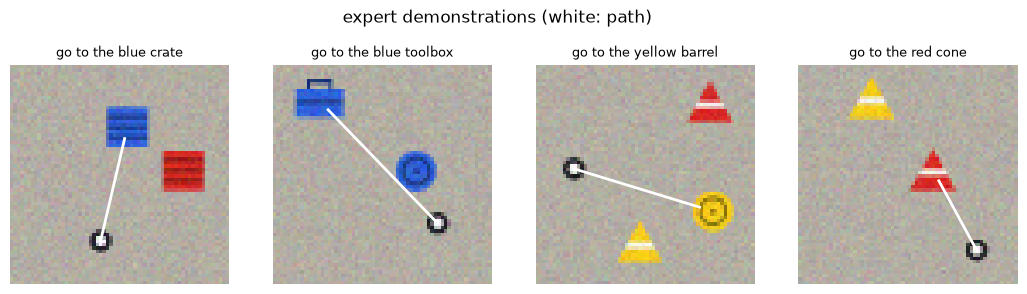

In [2]:
env = DepotNav()
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
for k, ax in enumerate(axs):
    o = env.reset(seed=k + 3)
    traj, done = [env.p.copy()], False
    first = o["image"]
    while not done:
        o, done, ok = env.step(env.expert_action())
        traj.append(env.p.copy())
    traj = np.array(traj)
    ax.imshow(first, extent=(0, 1, 1, 0)); ax.plot(traj[:, 0], traj[:, 1], "w-", lw=2)
    ax.set_title(o["instruction"], fontsize=9); ax.axis("off")
plt.suptitle("expert demonstrations (white: path)"); plt.show()

Collect two datasets of 12 000 episodes each, differing only in how scenes and instructions are paired:

* **A — one instruction per scene** (the way demonstrations are often recorded: set up a scene, do a task);
* **B — three instructions per scene**: the same objects, three different tasks and starts.

In [3]:
t0 = time.time()
D_A = collect(12_000, seed=1, chunk=8, tasks_per_scene=1)
D_B = collect(12_000, seed=1, chunk=8, tasks_per_scene=3)
print(f"collected in {time.time() - t0:.0f} s: A {len(D_A['action'])} steps, B {len(D_B['action'])} steps")


def tensors(D):
    return (torch.as_tensor(D["image"]), torch.as_tensor(pad_instructions(D["instruction"], 5)),
            torch.as_tensor(D["state"]), torch.as_tensor(D["chunk"]))


DATA = {"A": tensors(D_A), "B": tensors(D_B)}
X, I, S, A = DATA["B"]
print("images", tuple(X.shape), "uint8 | instructions", tuple(I.shape), "| state", tuple(S.shape),
      "| action chunks", tuple(A.shape), "(B, H_a = 8, d_a = 2)")
print("vocabulary:", len(INSTR_VOCAB), "words; 'go to the red toolbox' ->", encode_instruction("go to the red toolbox"))

collected in 258 s: A 139355 steps, B 139463 steps
images (139463, 64, 64, 3) uint8 | instructions (139463, 5) | state (139463, 2) | action chunks (139463, 8, 2) (B, H_a = 8, d_a = 2)
vocabulary: 44 words; 'go to the red toolbox' -> [42, 43, 32, 30, 35]


Held-out data for an *offline* metric: action error on demonstrations from unseen scenes.

In [4]:
V = collect(300, seed=999, chunk=8)
XV, IV = to_tensor(V["image"][:2000]).to(dev), torch.as_tensor(pad_instructions(V["instruction"], 5))[:2000].to(dev)
SV, AV = torch.as_tensor(V["state"][:2000]).to(dev), torch.as_tensor(V["chunk"][:2000]).to(dev)

## 2. The model, and its tokens
`TinyVLA` (book 8.1): 64 image-patch tokens from the ViT, the instruction's word tokens, one state token, a
4-layer bidirectional transformer, and an action head.

In [5]:
def new_vla(head):
    clip = TinyCLIP(len(scenes.VOCAB))
    if CKPT.exists():
        clip.load_state_dict(torch.load(CKPT, map_location="cpu"))
    return TinyVLA(len(INSTR_VOCAB), head=head, vision=clip.image_encoder).to(dev)


m = new_vla("flow")
for name, part in [("vision (ViT)", m.vision), ("backbone blocks", m.blocks), ("flow expert", m.expert)]:
    print(f"{name:16s} {sum(p.numel() for p in part.parameters()):>9,} parameters")
print(f"{'total':16s} {sum(p.numel() for p in m.parameters()):>9,}")
with torch.no_grad():
    x, key = m._prefix(to_tensor(X[:2]).to(dev), I[:2].to(dev), S[:2].to(dev))
print("observation tokens", tuple(x.shape), "= 64 image + 5 instruction + 1 state; padding mask row 0:",
      key[0, 64:].int().tolist())

vision (ViT)     1,082,880 parameters
backbone blocks  1,049,600 parameters
flow expert        682,754 parameters
total            2,854,786
observation tokens (2, 70, 128) = 64 image + 5 instruction + 1 state; padding mask row 0: [1, 1, 1, 1, 0, 1]


## 3. Training and evaluation utilities
Behavioural cloning on 128-sample batches, AdamW, one-cycle schedule. Closed-loop evaluation steps 200 episodes
on *new* scenes in lockstep (`vlacourse.depot_env.evaluate`); success rates come with 95% Wilson intervals
(book 9.5).

In [6]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


def train_vla(head, data="B", freeze_vision=True, steps=5000, seed=0):
    set_seed(seed)
    m = new_vla(head)
    X, I, S, A = DATA[data]
    vis = list(m.vision.parameters())
    ids = {id(p) for p in vis}
    rest = [p for p in m.parameters() if id(p) not in ids]
    if freeze_vision:
        for p in vis:
            p.requires_grad = False
        groups, lrs = [{"params": rest, "lr": 3e-4}], [3e-4]
    else:
        groups, lrs = [{"params": vis, "lr": 1e-4}, {"params": rest, "lr": 3e-4}], [1e-4, 3e-4]
    opt = torch.optim.AdamW(groups, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lrs, total_steps=steps, pct_start=0.05)
    t0 = time.time()
    for _ in range(steps):
        j = torch.randint(0, len(X), (128,))
        loss = m.loss(to_tensor(X[j]).to(dev), I[j].to(dev), S[j].to(dev), A[j].to(dev))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
    m.eval()
    with torch.no_grad():
        P = torch.cat([m.act(XV[k:k + 500], IV[k:k + 500], SV[k:k + 500]) for k in range(0, len(XV), 500)])
    heldout = (P - AV).abs().mean().item()
    print(f"[{head}, data {data}, vision {'frozen' if freeze_vision else 'fine-tuned'}] "
          f"train loss {loss.item():.4f}, held-out |action error| {heldout:.3f} ({time.time() - t0:.0f} s)")
    return m


def policy_of(m, **kw):
    def pol(img, ins, st):
        with torch.no_grad():
            return m.act(to_tensor(img).to(dev), torch.as_tensor(ins).to(dev), torch.as_tensor(st).to(dev), **kw).cpu().numpy()
    return pol


def closed_loop(m, label, n=200, **kw):
    r = evaluate(policy_of(m), n, **kw)
    s, amb = r["success"], r["ambiguous"]
    lo, hi = wilson(s.sum(), len(s))
    print(f"{label:38s} success {s.mean():.2f} [{lo:.2f}, {hi:.2f}]   specific {s[~amb].mean():.2f}   "
          f"ambiguous {s[amb].mean():.2f}   mean steps {r['steps'].mean():.1f}")
    return r

## 4. A first VLA — and a shortcut
Regression head, dataset A (one instruction per scene), vision encoder fine-tuned with the rest (as OpenVLA does).

In [7]:
naive = train_vla("mse", data="A", freeze_vision=False)
r_naive = closed_loop(naive, "MSE, data A, vision fine-tuned", execute=4)

[mse, data A, vision fine-tuned] train loss 0.0519, held-out |action error| 0.299 (421 s)


MSE, data A, vision fine-tuned         success 0.57 [0.50, 0.64]   specific 0.55   ambiguous 0.74   mean steps 31.2


The training loss is small but the held-out error is large, and in closed loop the policy succeeds far more
often on *ambiguous* instructions than on specific ones. Where do failed episodes end?

In [8]:
def failure_analysis(m, n=100, seed=20_000):
    pol = policy_of(m)
    wrong = lost = 0
    for i in range(n):
        env = DepotNav(); o = env.reset(seed + i)
        ins = pad_instructions([encode_instruction(o["instruction"])], 5)
        done = ok = False
        while not done:
            for a in pol(o["image"][None], ins, o["state"][None])[0][:4]:
                o, done, ok = env.step(a)
                if done:
                    break
        if not ok:
            near = min(np.hypot(*(env.p - [q.x, q.y])) for q in env.scene.objects) < 0.1
            wrong += near; lost += not near
    print(f"failures out of {n}: {wrong} at the WRONG object, {lost} near no object")


failure_analysis(naive)

failures out of 100: 26 at the WRONG object, 20 near no object


Most failures end at a *wrong object*: the robot drives competently, but to whatever object it associates with
the scene. In dataset A every scene appears with exactly one task, so "which scene is this?" predicts the action
as well as "what does the instruction say?" — and memorising scenes is easier than grounding words in pixels.
Ambiguous instructions accept several objects, so heading for *some* object succeeds more often. This is the
instruction-ignoring **shortcut** of book 9.6, and real VLAs trained on scene-per-task data show it too.

## 5. The fix: break the shortcut in the data, and protect the pretrained encoder
Two changes: dataset B pairs every scene with three tasks, so only the instruction predicts which object to go
to; and the vision encoder is **frozen**, so its million parameters cannot memorise the training scenes. (With
OpenVLA's ~1 M episodes, fine-tuning the encoder helped; with this lab's ~10 k scenes, freezing generalises
better — the right choice depends on the data, book 3.4 and 9.4.)

In [9]:
mse = train_vla("mse", data="B", freeze_vision=True)
r_mse = closed_loop(mse, "MSE, data B, vision frozen", execute=4)
failure_analysis(mse)

[mse, data B, vision frozen] train loss 0.0470, held-out |action error| 0.170 (308 s)


MSE, data B, vision frozen             success 0.84 [0.78, 0.88]   specific 0.85   ambiguous 0.79   mean steps 20.0


failures out of 100: 10 at the WRONG object, 5 near no object


## 6. Three action heads, same backbone and data
The token head (book 8.4) discretises each of the 8 × 2 action numbers into 32 bins and decodes the 16 tokens
autoregressively *with the backbone*, under a prefix-LM mask. The flow head (book 8.5) runs the backbone once
and a 2-layer cross-attention expert 10 times.

Generative heads learn a whole distribution over chunks rather than its mean, and they converge more slowly:
at the regression head's 5 000 steps they reach only about 0.3 success here. They are trained for 15 000 steps.

In [10]:
tok = train_vla("tokens", data="B", freeze_vision=True, steps=15_000)

[tokens, data B, vision frozen] train loss 0.0383, held-out |action error| 0.425 (1067 s)


In [11]:
flow = train_vla("flow", data="B", freeze_vision=True, steps=15_000)

[flow, data B, vision frozen] train loss 0.1201, held-out |action error| 0.363 (969 s)


In [12]:
results = {}
for name, model in [("MSE", mse), ("tokens", tok), ("flow", flow)]:
    results[name] = closed_loop(model, f"{name} head, execute 4 of 8", execute=4)
Path("../../data/checkpoints").mkdir(parents=True, exist_ok=True)
for name, model in [("mse", mse), ("flow", flow)]:              # Lab 12 transfers these to MuJoCo
    torch.save(model.state_dict(), f"../../data/checkpoints/toy_vla_{name}.pt")

MSE head, execute 4 of 8               success 0.84 [0.78, 0.88]   specific 0.85   ambiguous 0.79   mean steps 20.0


tokens head, execute 4 of 8            success 0.49 [0.43, 0.56]   specific 0.46   ambiguous 0.84   mean steps 36.1


flow head, execute 4 of 8              success 0.50 [0.43, 0.57]   specific 0.46   ambiguous 0.89   mean steps 34.7


Read the split by instruction type, not only the total. On **ambiguous** instructions the generative heads are
at least as good as regression: they commit to one of the valid objects. But here regression also copes, because
closed-loop feedback breaks the tie — once the robot drifts slightly towards one object, every later observation
favours it (compare Lab 09, where the decision had to be made in one shot).

On **specific** instructions the generative heads are clearly worse than regression, even after three times as
many training steps. A head that can represent several modes can *hedge*: if the language conditioning is weak,
a mixture over all the objects in the scene fits the data almost as well as using the instruction, and sampling
from it sometimes picks the wrong object. Regression cannot hedge cheaply (averaging two objects costs a large
squared error on every sample), so it is pushed harder to use the instruction. Expressiveness is not free: a
generative head needs strong conditioning — more data and training, or classifier-free guidance (exercise 7) —
to turn its flexibility into the right commitment.

## 7. Execution schemes (book 8.6)
Flow head: re-plan every step ($H_e=1$), execute 4 or all 8 actions, or re-plan every step with ACT-style
temporal ensembling.

In [13]:
schemes = {}
for label, kw in [("H_e = 1 (receding horizon)", dict(execute=1)), ("H_e = 4", dict(execute=4)),
                  ("H_e = 8 (whole chunk)", dict(execute=8)), ("temporal ensembling, m = 0.1", dict(ensemble_m=0.1))]:
    schemes[label] = closed_loop(flow, f"flow, {label}", **kw)

flow, H_e = 1 (receding horizon)       success 0.38 [0.32, 0.45]   specific 0.34   ambiguous 0.74   mean steps 37.8


flow, H_e = 4                          success 0.54 [0.47, 0.61]   specific 0.50   ambiguous 0.89   mean steps 34.6


flow, H_e = 8 (whole chunk)            success 0.67 [0.60, 0.73]   specific 0.65   ambiguous 0.89   mean steps 31.4


flow, temporal ensembling, m = 0.1     success 0.25 [0.20, 0.31]   specific 0.23   ambiguous 0.42   mean steps 44.3


For the flow head, the more it commits, the better: re-planning every step ($H_e=1$) draws a fresh sample each
step, and consecutive samples can head for different objects, so the robot dithers; executing whole chunks keeps
one decision for 0.8 s and succeeds most often. Temporal ensembling is the worst scheme: it averages actions from
*different* samples — mode averaging reintroduced at execution time (book 6.1, 8.6). With a stochastic head,
commit to one chunk at a time, and re-plan only as often as the task's reactivity requires.

## 8. What each head costs (book 6.6, 8.7)
Time one action chunk for one observation (batch 1, as on a robot), split into backbone and head.

In [14]:
def time_it(fn, n=30):
    if dev.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    if dev.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000


img1, ins1, st1 = to_tensor(X[:1]).to(dev), I[:1].to(dev), S[:1].to(dev)
with torch.no_grad():
    t_backbone = time_it(lambda: flow.encode(img1, ins1, st1))
    rows = [("MSE", time_it(lambda: mse.act(img1, ins1, st1))),
            ("tokens (16 backbone passes)", time_it(lambda: tok.act(img1, ins1, st1))),
            ("flow, 10 Euler steps", time_it(lambda: flow.act(img1, ins1, st1, steps=10))),
            ("flow, 2 Euler steps", time_it(lambda: flow.act(img1, ins1, st1, steps=2)))]
print(f"one backbone pass: {t_backbone:.2f} ms")
for name, t in rows:
    print(f"{name:30s} {t:6.2f} ms per chunk of 8 actions")

one backbone pass: 1.94 ms
MSE                              2.03 ms per chunk of 8 actions
tokens (16 backbone passes)     35.51 ms per chunk of 8 actions
flow, 10 Euler steps            10.21 ms per chunk of 8 actions
flow, 2 Euler steps              3.65 ms per chunk of 8 actions


The token head pays a backbone pass per action number; the flow head pays one backbone pass plus cheap expert
steps — the asymmetry of book 6.6, measured. (At this toy scale Python and kernel-launch overhead blur the
numbers; for a billion-parameter backbone the token head's cost grows with the backbone and the expert's does not.)

## Exercises
1. Separate the two fixes of §5: train with data B but a fine-tuned encoder, and with data A but a frozen
   encoder. Which change matters more here?
2. Make all instructions ambiguous at test time by adding a second object of the same colour to every scene.
   How does each head's success change? Look at trajectories that fail.
3. Change the action space to *absolute goal positions* (the target's coordinates) instead of velocities. What
   happens to success and to robustness against a moved object (book 8.3)?
4. Move the robot's camera: render the training images with the agent drawn in a different colour, evaluate on
   the original. What does this say about input pipelines (book 8.2)?
5. Sweep the number of flow steps from 1 to 20 and plot success against latency.
6. Robotics: run the policy on the MuJoCo depot of Lab 12 without retraining. Explain the result.
7. **Stronger conditioning.** Train the flow head with the instruction dropped (replaced by padding) for 10% of
   samples, then sample with classifier-free guidance, $v=v_\varnothing+w\,(v_\ell-v_\varnothing)$, for
   $w=1,2,3$. Does success on specific instructions improve? Also compute action-sample disagreement (book 11.5)
   for specific vs ambiguous instructions.